<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:26px 28px;border-radius:12px;color:#fff"><h1 style="margin:0;color:#fff">CSR Projects by Companies in India (2014 to 2020)</h1></div>

<div style="background:#F5F9FF;border:1px solid #BBD3EE;padding:14px 20px;border-radius:10px;color:#1B1B1B"><h3 style="margin:0 0 8px 0;color:#1F4E79">Project overview</h3><p><b>Problem statement:</b> To analyse CSR projects reported by Indian companies between 2014 and 2020, to understand how CSR spending is distributed across development sectors, states and companies, and how it changed over time.</p><p><b>Domain:</b> Corporate Social Responsibility (CSR), the money companies spend on social causes such as education and health.</p><p><b>Objectives:</b> Clean the data, find which sectors, states and companies get or give the most CSR money, study the change over the years, and compare government and other companies.</p><p><b>Dataset:</b> 36,664 projects and 17 columns (numbers, dates and text), 693 companies, years 2014 to 2020. Amounts are in lakhs (1 crore = 100 lakhs).</p><p><b>Source:</b> <span style="background:#FFF3E0;color:#E65100;padding:1px 6px">https://indiadataportal.com</span></p></div>

<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:14px 20px;border-radius:10px;color:#fff"><h2 style="margin:0;color:#fff">1. Import Libraries and Load Data</h2></div>

I import the libraries. pandas works with tables, numpy handles numbers, matplotlib and seaborn draw the charts, and plotly draws interactive charts that I can hover over.

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

The data is an Excel file saved in my GitHub repository, so I load it from the link. I show the first five rows to check that it was read correctly.

In [29]:
df = pd.read_excel("https://raw.githubusercontent.com/Dheeraj-S-Pillai/DACAPSTONE_PROJECT/main/csr-projects-by-companies.xlsx")
df.head()

,id,year,state_name,state_code,district_name,district_code,csr_project_name,development_sector,company_name,cin,company_class,company_type,roc,company_category,listing_status,project_outlay_amount_in_lakhs,amount_spent_in_lakhs
0,28,2014-01-01,Gujarat,24,Bhavnagar,443,RotaryAcrysil Child Educare Project,Health Care,Acrysil Limited,L26914MH1987PLC042283,Public,Other than Govt. Companies,ROC-MUMBAI,Company limited by Shares,Listed,12.0,12.0
1,30,2014-01-01,Gujarat,24,Prayagraj,438,Adani Vidya Mandir,Education,Adani Enterprises Limited,L51100GJ1993PLC019067,Public,Other than Govt. Companies,ROC-AHMEDABAD,Company limited by Shares,Listed,176.0,176.0
2,31,2014-01-01,Gujarat,24,Prayagraj,438,Project Udaan,Education,Adani Enterprises Limited,L51100GJ1993PLC019067,Public,Other than Govt. Companies,ROC-AHMEDABAD,Company limited by Shares,Listed,20.0,20.0
3,82,2014-01-01,Tamil Nadu,33,Kancheepuram,574,Painting School For Leprosy Students Rising St...,Education,Akzo Nobel India Limited,L24292WB1954PLC021516,Public,Other than Govt. Companies,ROC-KOLKATA,Company limited by Shares,Listed,7.0,7.0
4,83,2014-01-01,Maharashtra,27,Pune,490,Educational Material Distribution,Education,Akzo Nobel India Limited,L24292WB1954PLC021516,Public,Other than Govt. Companies,ROC-KOLKATA,Company limited by Shares,Listed,0.0,0.0


`tail()` shows the last five rows, to check that the data ends properly and has no blank rows.

In [30]:
df.tail()

,id,year,state_name,state_code,district_name,district_code,csr_project_name,development_sector,company_name,cin,company_class,company_type,roc,company_category,listing_status,project_outlay_amount_in_lakhs,amount_spent_in_lakhs
36659,37434,2020-01-01,All India,0,Not Mentioned,0,Eradicating Hunger Poverty And Malnutrition Pr...,Health Care,Wipro Limited,L32102KA1945PLC020800,Public,Other than Govt. Companies,ROC-BANGALORE,Company limited by Shares,Listed,3080.0,3080.0
36660,37456,2020-01-01,All India,0,Not Mentioned,0,Donation To Pm Cares Fund,Other Central Government Funds,Yasho Industries Limited,L74110MH1985PLC037900,Public,Other than Govt. Companies,ROC-MUMBAI,Company limited by Shares,Listed,5.0,5.0
36661,37463,2020-01-01,All India,0,Not Mentioned,0,Csr Support To Build School For Girls,Education,Zee Entertainment Enterprises Limited,L92132MH1982PLC028767,Public,Other than Govt. Companies,ROC-MUMBAI,Company limited by Shares,Listed,330.0,330.0
36662,37464,2020-01-01,All India,0,Not Mentioned,0,Csr Support To Indian Institute Of Development,Education,Zee Entertainment Enterprises Limited,L92132MH1982PLC028767,Public,Other than Govt. Companies,ROC-MUMBAI,Company limited by Shares,Listed,1320.0,1320.0
36663,37465,2020-01-01,All India,0,Not Mentioned,0,Covid Related Csr Spends,Health Care,Zee Entertainment Enterprises Limited,L92132MH1982PLC028767,Public,Other than Govt. Companies,ROC-MUMBAI,Company limited by Shares,Listed,3350.0,3350.0


**Observation:** The last rows are all from 2020 and have no empty values, so the data looks complete at the end. The rows are sorted by year.

<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:14px 20px;border-radius:10px;color:#fff"><h2 style="margin:0;color:#fff">2. First Look at the Data</h2></div>

Number of rows and columns.

In [31]:
df.shape

(36664, 17)

`info()` shows the data type of each column and how many values are not empty.

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36664 entries, 0 to 36663
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              36664 non-null  int64         
 1   year                            36664 non-null  datetime64[us]
 2   state_name                      36664 non-null  str           
 3   state_code                      36664 non-null  int64         
 4   district_name                   36664 non-null  str           
 5   district_code                   36664 non-null  int64         
 6   csr_project_name                36661 non-null  str           
 7   development_sector              36664 non-null  str           
 8   company_name                    36664 non-null  str           
 9   cin                             36664 non-null  str           
 10  company_class                   36664 non-null  str           
 11  company_type 

**Observation:** The data has 36,664 rows and 17 columns. Only `csr_project_name` has empty cells. The `year` column is a date, and the two amount columns are decimal numbers.

`describe()` gives the summary of the two amount columns.

In [33]:
df[["project_outlay_amount_in_lakhs", "amount_spent_in_lakhs"]].describe()

,project_outlay_amount_in_lakhs,amount_spent_in_lakhs
count,3.666400e+04,36664.000000
mean,1.239896e+06,155.563992
std,5.723989e+07,1077.844685
min,-2.000000e+01,-63.000000
25%,2.000000e+00,2.000000
50%,1.250000e+01,10.000000
75%,6.770500e+01,50.000000
max,6.632645e+09,55389.000000


<div style="background:#E8F5E9;border-left:6px solid #2E7D32;padding:8px 14px;color:#1B1B1B"><b style="color:#2E7D32">Initial observations:</b> the amount spent has a negative minimum (-63), and the planned outlay has a huge maximum of about 6.6 billion lakhs while its median is only 12.5. Both are checked in the cleaning step.</div>

<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:14px 20px;border-radius:10px;color:#fff"><h2 style="margin:0;color:#fff">3. Data Cleaning</h2></div>

**3.1 Missing values.** I count the empty cells in each column.

In [34]:
df.isnull().sum()

id                                0
year                              0
state_name                        0
state_code                        0
district_name                     0
district_code                     0
csr_project_name                  3
development_sector                0
company_name                      0
cin                               0
company_class                     0
company_type                      0
roc                               0
company_category                  0
listing_status                    0
project_outlay_amount_in_lakhs    0
amount_spent_in_lakhs             0
dtype: int64

Only 3 project names are empty. I fill them with `Not Mentioned`, so these rows are kept.

In [35]:
df["csr_project_name"] = df["csr_project_name"].fillna("Not Mentioned")

**3.2 Hidden missing values.** Some cells contain the text `Not Mentioned`. I count them in the main columns.

In [36]:
for col in ["state_name", "district_name", "development_sector"]:
    print(col, ":", (df[col] == "Not Mentioned").sum())

state_name : 667
district_name : 24277
development_sector : 1572


<div style="background:#FFF3E0;border-left:6px solid #E65100;padding:8px 14px;color:#1B1B1B"><b style="color:#E65100">Decision:</b> district has 24,277 rows (66%), sector 1,572 and state 667 marked `Not Mentioned`. These rows have valid amounts, so they are kept. They are left out only when ranking that column, and district analysis is not done.</div>

**3.3 Duplicates.** The `id` column is different in every row and is not useful for analysis, so I drop it. Then I check for duplicate rows and remove them.

In [37]:
df = df.drop(columns=["id"])
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicate rows: 0


**Observation:** There are no duplicate rows.

**3.4 Data type.** The `year` column is a date, but only the year is needed, so I keep the year number.

In [38]:
df["year"] = df["year"].dt.year
df["year"].value_counts().sort_index()

year
2014    3268
2015    4740
2016    5136
2017    5285
2018    6022
2019    6234
2020    5979
Name: count, dtype: int64

**3.5 Extra spaces.** Extra spaces make the same text look like different values, so I remove the spaces at the start and end of the text columns.

In [39]:
text_cols = ["state_name", "district_name", "csr_project_name", "development_sector",
             "company_name", "company_class", "company_type", "company_category", "listing_status"]

for col in text_cols:
    df[col] = df[col].str.strip()

**3.6 Inconsistent labels.** `PLC` means Public Limited Company, so it is changed to `Public`. The short form `Govt.` is written in full, and one sector name has a wrong capital letter.

In [40]:
df["company_class"] = df["company_class"].replace("PLC", "Public")
df["company_type"] = df["company_type"].replace({"Govt. Companies": "Government Companies",
                                                 "Other than Govt. Companies": "Other than Government Companies"})
df["development_sector"] = df["development_sector"].replace("Prime Minister'S National Relief Fund",
                                                            "Prime Minister's National Relief Fund")
df["company_class"].value_counts()

company_class
Public     36479
Private      185
Name: count, dtype: int64

**3.7 Negative amounts.** Money cannot be negative, so I count these rows and remove them.

In [41]:
print("Negative outlay:", (df["project_outlay_amount_in_lakhs"] < 0).sum())
print("Negative spent:", (df["amount_spent_in_lakhs"] < 0).sum())

df = df[(df["project_outlay_amount_in_lakhs"] >= 0) & (df["amount_spent_in_lakhs"] >= 0)]
print("Rows left:", len(df))

Negative outlay: 1
Negative spent: 3
Rows left: 36660


**3.8 Very large and zero amounts.** I check how many planned outlays are above 10,00,000 lakhs (10,000 crore), and how many projects spent nothing.

In [42]:
print("Outlay above 10,00,000 lakhs:", (df["project_outlay_amount_in_lakhs"] > 1000000).sum())
print("Largest outlay:", df["project_outlay_amount_in_lakhs"].max())
print("Projects with zero spent:", (df["amount_spent_in_lakhs"] == 0).sum())

Outlay above 10,00,000 lakhs: 194
Largest outlay: 6632644600.0
Projects with zero spent: 3624


<div style="background:#FFF3E0;border-left:6px solid #E65100;padding:8px 14px;color:#1B1B1B"><b style="color:#E65100">Decision:</b> 194 planned outlays are above 10,00,000 lakhs and the largest is about 6.6 billion lakhs, which is not possible for one project. They look like entry mistakes, but I cannot prove it, so the rows are kept. The outlay column is not used for totals or averages, and the amount spent is the main measure. Zero-spend projects are also kept.</div>

**3.9 Short column names.** I rename the two long amount columns.

In [43]:
df = df.rename(columns={"project_outlay_amount_in_lakhs": "outlay_lakhs",
                        "amount_spent_in_lakhs": "spent_lakhs"})

**3.10 New columns.** `spent_crore` shows the amount in crore (1 crore = 100 lakhs). `project_size` groups the projects by the amount spent, using `pd.cut`.

In [44]:
df["spent_crore"] = df["spent_lakhs"] / 100

bins = [-1, 10, 100, 1000, 100000]
labels = ["Small", "Medium", "Large", "Very large"]
df["project_size"] = pd.cut(df["spent_lakhs"], bins=bins, labels=labels)

df["project_size"].value_counts()

project_size
Small         18437
Medium        12334
Large          4925
Very large      964
Name: count, dtype: int64

**Observation:** Small means up to 10 lakhs, Medium up to 100, Large up to 1,000 and Very large above 1,000 lakhs.

**3.11 Final check.** After cleaning I check the shape, the missing values and the first rows.

In [45]:
print(df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

(36660, 18)
Missing values: 0


,year,state_name,state_code,district_name,district_code,csr_project_name,development_sector,company_name,cin,company_class,company_type,roc,company_category,listing_status,outlay_lakhs,spent_lakhs,spent_crore,project_size
0,2014,Gujarat,24,Bhavnagar,443,RotaryAcrysil Child Educare Project,Health Care,Acrysil Limited,L26914MH1987PLC042283,Public,Other than Government Companies,ROC-MUMBAI,Company limited by Shares,Listed,12.0,12.0,0.12,Medium
1,2014,Gujarat,24,Prayagraj,438,Adani Vidya Mandir,Education,Adani Enterprises Limited,L51100GJ1993PLC019067,Public,Other than Government Companies,ROC-AHMEDABAD,Company limited by Shares,Listed,176.0,176.0,1.76,Large
2,2014,Gujarat,24,Prayagraj,438,Project Udaan,Education,Adani Enterprises Limited,L51100GJ1993PLC019067,Public,Other than Government Companies,ROC-AHMEDABAD,Company limited by Shares,Listed,20.0,20.0,0.20,Medium
3,2014,Tamil Nadu,33,Kancheepuram,574,Painting School For Leprosy Students Rising St...,Education,Akzo Nobel India Limited,L24292WB1954PLC021516,Public,Other than Government Companies,ROC-KOLKATA,Company limited by Shares,Listed,7.0,7.0,0.07,Small
4,2014,Maharashtra,27,Pune,490,Educational Material Distribution,Education,Akzo Nobel India Limited,L24292WB1954PLC021516,Public,Other than Government Companies,ROC-KOLKATA,Company limited by Shares,Listed,0.0,0.0,0.00,Small


<div style="background:#E8F5E9;border-left:6px solid #2E7D32;padding:8px 14px;color:#1B1B1B"><b style="color:#2E7D32">Cleaning summary:</b> Here is what I did to clean the data.<ul style="margin:6px 0 0 18px;padding:0"><li>I removed 4 rows that had negative money amounts, because money cannot be negative.</li><li>I filled the 3 empty project names with <code>Not Mentioned</code>.</li><li>I dropped the <code>id</code> column because it is not useful for the analysis.</li><li>I turned the date in the <code>year</code> column into a simple year number.</li><li>I removed extra spaces and fixed labels, for example <code>PLC</code> became <code>Public</code>.</li><li>I added two new columns, <code>spent_crore</code> and <code>project_size</code>.</li></ul>Now the data has 36,660 rows and 18 columns, and no missing values.</div>

<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:14px 20px;border-radius:10px;color:#fff"><h2 style="margin:0;color:#fff">4. Exploratory Data Analysis</h2><p style="margin:4px 0 0 0;color:#fff">Univariate, bivariate and multivariate analysis with charts</p></div>

### 4.1 Univariate analysis (one variable at a time)

**Projects by sector.** I leave out the projects whose sector is `Not Mentioned` and show the 10 sectors with the most projects.

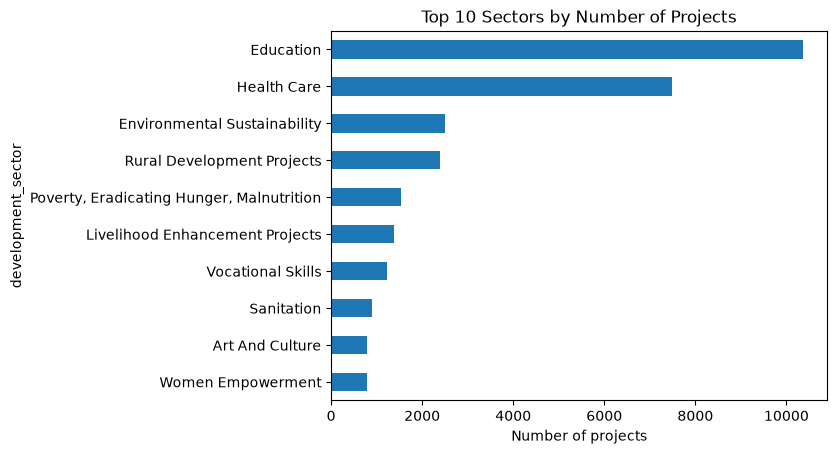

In [46]:
sector_df = df[df["development_sector"] != "Not Mentioned"]

sector_df["development_sector"].value_counts().head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Sectors by Number of Projects")
plt.xlabel("Number of projects")
plt.show()

**Observation:** Education has the most projects (10,375), followed by Health Care (7,491), Environmental Sustainability (2,508) and Rural Development (2,401).

**Projects by company type.**

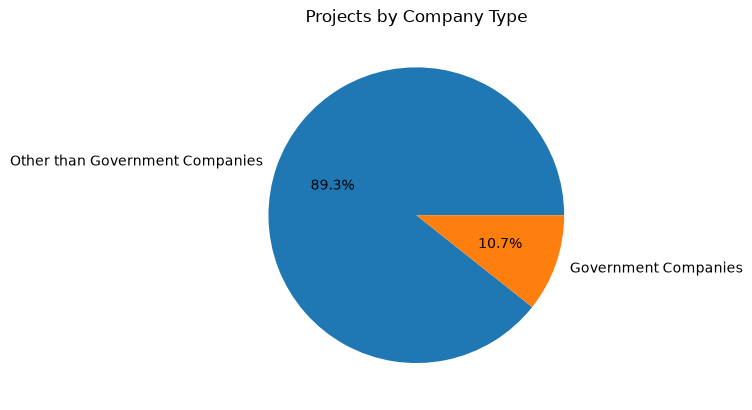

In [47]:
df["company_type"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Projects by Company Type")
plt.ylabel("")
plt.show()

**Observation:** About 89% of the projects are by companies other than government companies, and about 11% by government companies.

**Amount spent per project.** A histogram and a box plot side by side (subplots). I use a log scale because a few projects are very large, and leave out projects with zero spent.

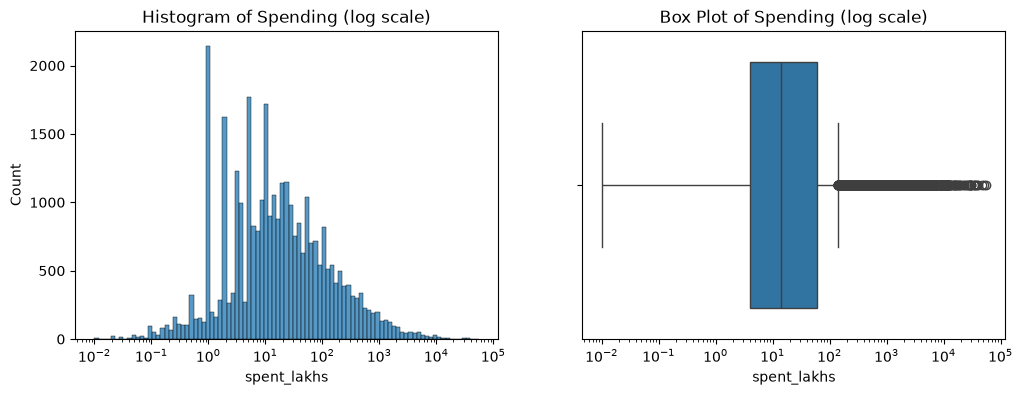

Mean spent (lakhs): 155.6
Median spent (lakhs): 10.0


In [48]:
nonzero = df[df["spent_lakhs"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=nonzero, x="spent_lakhs", log_scale=True, ax=axes[0])
sns.boxplot(x=nonzero["spent_lakhs"], ax=axes[1])
axes[1].set_xscale("log")
axes[0].set_title("Histogram of Spending (log scale)")
axes[1].set_title("Box Plot of Spending (log scale)")
plt.show()

print("Mean spent (lakhs):", round(df["spent_lakhs"].mean(), 1))
print("Median spent (lakhs):", df["spent_lakhs"].median())

**Observation:** Most projects are small. The mean is 155.6 lakhs but the median is only 10 lakhs, so a few very large projects pull the average up. For this reason totals and medians are used, and not only averages.

### 4.2 Bivariate analysis (two variables together)

**Total spending by year.** `groupby` puts the rows of each year together, and `sum()` adds the amounts.

year
2014     5556.0
2015     6651.0
2016     6649.0
2017     7781.0
2018     9388.0
2019    11904.0
2020     9108.0
Name: spent_crore, dtype: float64


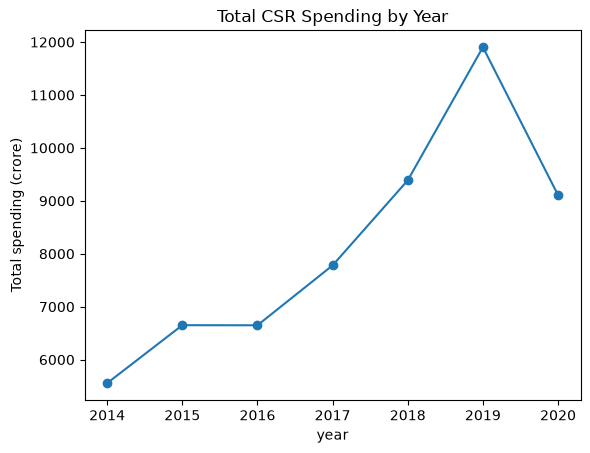

In [49]:
year_spending = df.groupby("year")["spent_crore"].sum()
print(year_spending.round(0))

year_spending.plot(kind="line", marker="o")
plt.title("Total CSR Spending by Year")
plt.ylabel("Total spending (crore)")
plt.show()

**Observation:** Spending rose from about 5,556 crore in 2014 to a peak of 11,904 crore in 2019, and then fell about 23% to 9,108 crore in 2020. The data does not tell us the reason for the fall.

**Total spending by sector.**

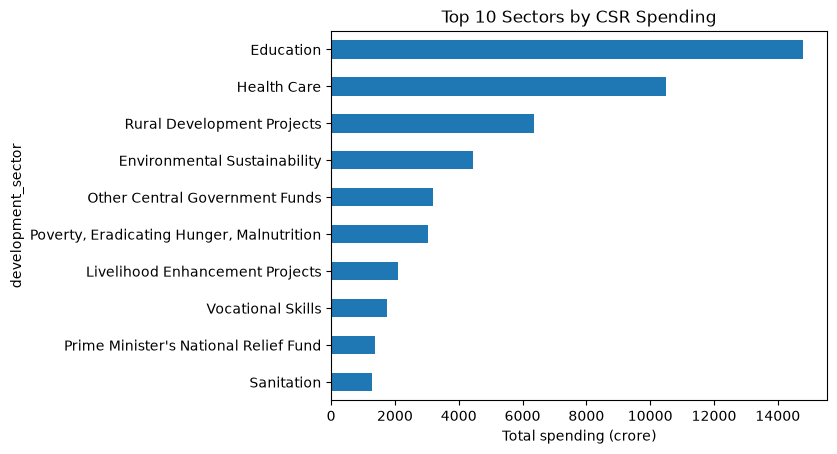

In [50]:
sector_spending = sector_df.groupby("development_sector")["spent_crore"].sum().sort_values(ascending=False).head(10)

sector_spending.sort_values().plot(kind="barh")
plt.title("Top 10 Sectors by CSR Spending")
plt.xlabel("Total spending (crore)")
plt.show()

**Observation:** Education (14,806 crore) and Health Care (10,505 crore) take the most money, about 44% of all spending together. Rural Development (6,358 crore) comes next.

**Total spending by state.** `All India` is kept as its own category, because it is how companies report projects that cover the whole country. Only `Not Mentioned` is left out, since it is missing information and not a place.

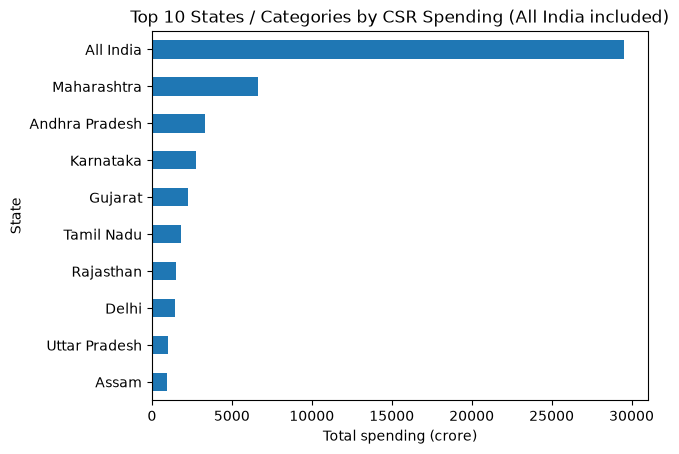

Share of spending marked All India (%): 51.8


In [51]:
# All India stays as a category; only "Not Mentioned" is removed
state_df = df[df["state_name"] != "Not Mentioned"]

state_totals = state_df.groupby("state_name")["spent_crore"].sum().sort_values(ascending=False)
state_totals.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 States / Categories by CSR Spending (All India included)")
plt.xlabel("Total spending (crore)")
plt.ylabel("State")
plt.show()

print("Share of spending marked All India (%):", round(state_totals["All India"] / df["spent_crore"].sum() * 100, 1))

**Observation:** `All India` is the biggest category by far, with about 52% of all spending, so it is bigger than every single state. Among real states, Maharashtra leads with about 6,609 crore, followed by Andhra Pradesh (3,294 crore) and Karnataka (2,768 crore). Because so much money is reported at the all-India level, the state totals understate the real spending in each state.

**Total spending by company.**

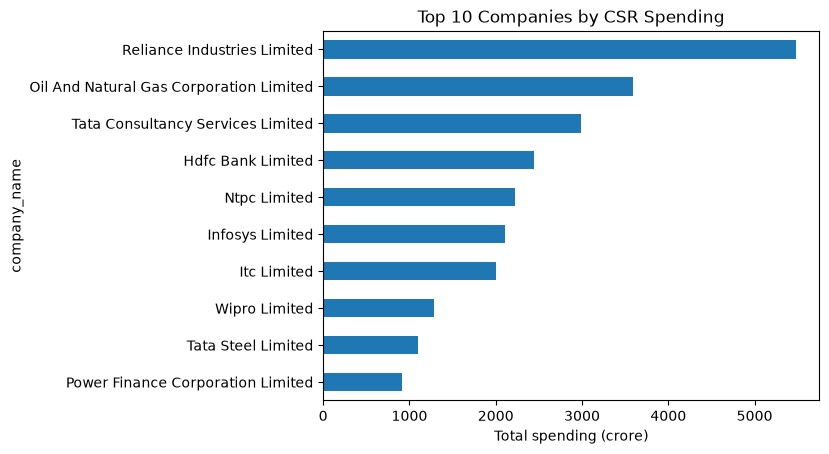

Share of the top 10 companies (%): 42.3


In [52]:
company_spending = df.groupby("company_name")["spent_crore"].sum().sort_values(ascending=False)

company_spending.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Companies by CSR Spending")
plt.xlabel("Total spending (crore)")
plt.show()

print("Share of the top 10 companies (%):", round(company_spending.head(10).sum() / company_spending.sum() * 100, 1))

**Observation:** Reliance Industries (5,475 crore), ONGC (3,588 crore) and TCS (2,989 crore) spend the most. The top 10 of the 693 companies give about 42% of all CSR money.

**Government companies compared with other companies.** `agg` gives the number of projects, the total and the median for each group.

In [53]:
df.groupby("company_type")["spent_crore"].agg(["count", "sum", "median"]).round(2)

,count,sum,median
company_type,,,
Government Companies,3913,14550.13,0.23
Other than Government Companies,32747,42486.45,0.10


**Observation:** Government companies run about 11% of the projects (3,913) but give about 26% of the spending. Their median project (0.23 crore) is bigger than that of other companies (0.10 crore), so they run fewer but larger projects.

**Planned outlay and amount spent.** A scatter plot shows if projects with a bigger plan also spend more. Both axes use a log scale because a few amounts are very large.

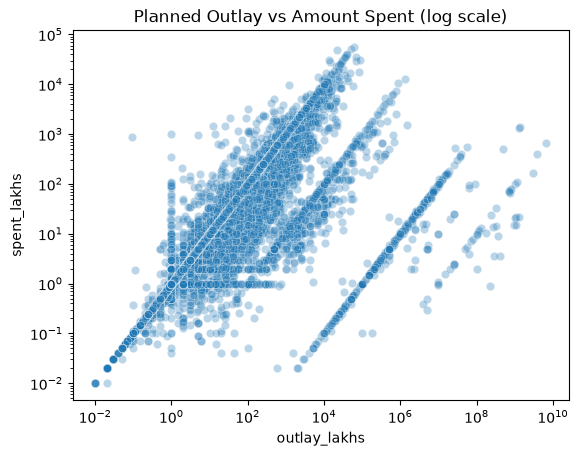

In [54]:
both = df[(df["outlay_lakhs"] > 0) & (df["spent_lakhs"] > 0)]

sns.scatterplot(data=both, x="outlay_lakhs", y="spent_lakhs", alpha=0.3)
plt.xscale("log")
plt.yscale("log")
plt.title("Planned Outlay vs Amount Spent (log scale)")
plt.show()



**Observation:** The dots follow a diagonal, so projects with a bigger plan generally spend more. A few extreme outlays sit far from the rest, which is another reason the outlay column is not used for totals.

### 4.3 Multivariate analysis (three or more variables)

**Sector, year and spending.** `pivot_table` makes a grid with sectors down the side and years across the top, and the heatmap colours each box by the amount.

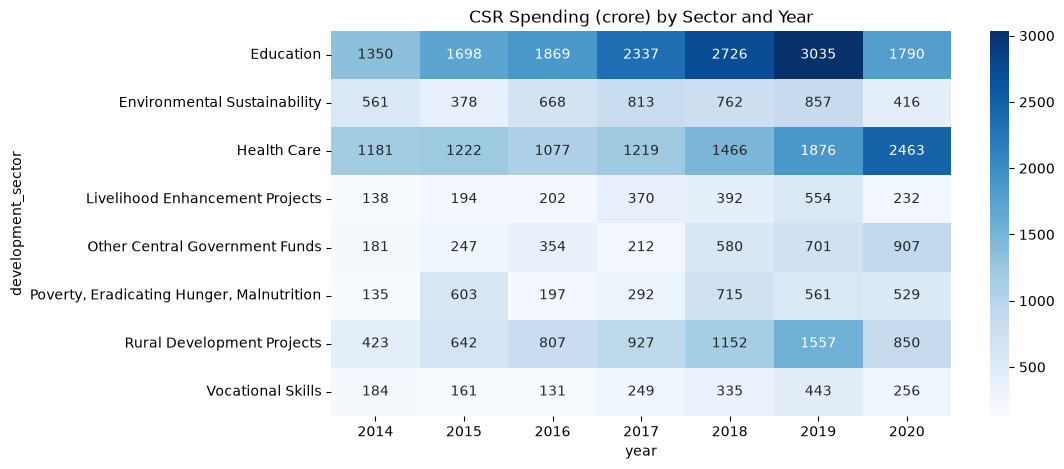

In [55]:
top8 = sector_spending.head(8).index
sector_year = sector_df[sector_df["development_sector"].isin(top8)].pivot_table(
    index="development_sector", columns="year", values="spent_crore", aggfunc="sum")

plt.figure(figsize=(10, 5))
sns.heatmap(sector_year, annot=True, fmt=".0f", cmap="Blues")
plt.title("CSR Spending (crore) by Sector and Year")
plt.show()

**Observation:** Education is the biggest sector in every year up to 2019 (3,035 crore), then falls to 1,790 crore in 2020. Health Care reaches its highest amount in 2020 (2,463 crore). The data cannot tell us the reason, although 2020 was the COVID-19 year.

**Year, company type and spending.** One line is drawn for each company type, and the legend explains the colours.

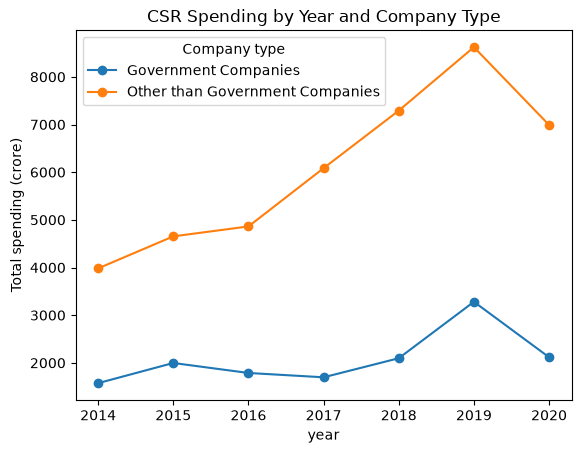

In [56]:
df.groupby(["year", "company_type"])["spent_crore"].sum().unstack().plot(kind="line", marker="o")
plt.title("CSR Spending by Year and Company Type")
plt.ylabel("Total spending (crore)")
plt.legend(title="Company type")
plt.show()

**Observation:** Both groups peak in 2019 and fall in 2020. Other companies grew from about 3,982 crore in 2014 to 8,623 crore in 2019, and government companies from about 1,574 crore to 3,281 crore.

**Year, planned outlay and amount spent.** A correlation heatmap of the three number columns. It compares the ranking of the values, so a few extreme amounts do not distort it.

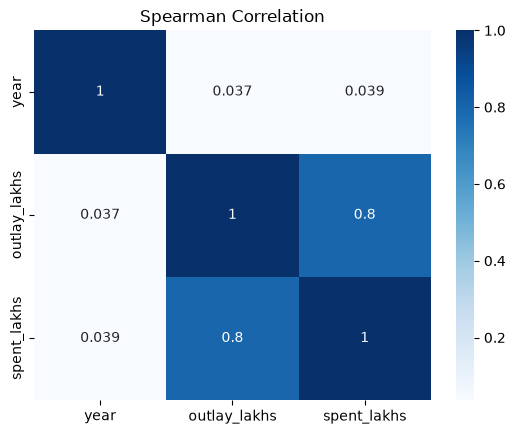

In [57]:
sns.heatmap(df[["year", "outlay_lakhs", "spent_lakhs"]].corr(method="spearman"), annot=True, cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

**Observation:** Planned and spent amounts are strongly related (0.80). Year has almost no relationship with either (0.04), so a typical project did not get bigger over the years. The yearly total grew because the number of projects grew.

### 4.4 Interactive charts with Plotly
Plotly charts are interactive. I can hover over a point to see its value, and click a name in the legend to hide or show that line.

**Spending by year for the top sectors.** I use the sector and year table (`sector_year`) made in section 4.3, so each line is one sector.

In [58]:
fig = px.line(sector_year.T, markers=True,
              title="Total Spending by Year for the Top 8 Sectors",
              labels={"value": "Total spending (crore)", "year": "Year", "development_sector": "Sector"})
fig.show()

**Observation:** Education is the highest line until 2019 and then drops sharply in 2020, while Health Care rises and becomes the highest line in 2020.

**Top 10 states by spending.** The same state chart as before, but now I can hover over each bar to see the exact amount.

In [59]:
top_states = state_df.groupby("state_name")["spent_crore"].sum().sort_values(ascending=False).head(10)

fig = px.bar(x=top_states.index, y=top_states.values,
             title="Top 10 States / Categories by CSR Spending (All India included)",
             labels={"x": "State", "y": "Total spending (crore)"})
fig.show()

**Observation:** `All India` is far above every state. Maharashtra is the highest real state, and the other states are much smaller.

<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:14px 20px;border-radius:10px;color:#fff"><h2 style="margin:0;color:#fff">5. Summary and Key Findings</h2></div>

<div style="background:#E8F5E9;border-left:6px solid #2E7D32;padding:8px 14px;color:#1B1B1B"><b style="color:#2E7D32">Summary:</b> I cleaned the CSR data and then studied it using tables and charts. These are the main things I found.<ol style="margin:6px 0 0 18px;padding:0"><li><b>Spending grew until 2019.</b> It went from about 5,556 crore in 2014 to 11,904 crore in 2019, which is more than double. In 2020 it fell by about 23% to 9,108 crore.</li><li><b>Education and Health Care get the most money.</b> Together they take about 44% of all spending (25,311 out of 57,037 crore).</li><li><b>More than half of the money (52%) is reported as All India.</b> It is the largest category, bigger than any state, and we cannot tell which state the money went to. Among real states, Maharashtra is first with 6,609 crore, almost double Andhra Pradesh (3,294 crore).</li><li><b>A few big companies give a large share.</b> The top 10 out of 693 companies give about 42% of all the money.</li><li><b>Government companies run fewer but bigger projects.</b> They run 11% of the projects but give about 26% of the money.</li><li><b>Most projects are small.</b> The average spend is 155.6 lakhs, but the middle value (median) is only 10 lakhs. A few very big projects pull the average up.</li><li><b>2020 looks different.</b> Health Care went up to 2,463 crore while Education went down to 1,790 crore. Health Care became the top sector for the first time. The interactive chart in section 4.4 shows this clearly.</li></ol></div>

<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:14px 20px;border-radius:10px;color:#fff"><h2 style="margin:0;color:#fff">6. Recommendations and Next Steps</h2></div>

<div style="background:#E3F2FD;border-left:6px solid #1565C0;padding:8px 14px;color:#1B1B1B"><b style="color:#1565C0">Recommendations:</b><ul style="margin:6px 0 0 18px;padding:0"><li>Companies should write the state and district of every project. Right now 52% of the money is marked All India and 66% of the projects have no district, so it is hard to compare regions.</li><li>The planned outlay should be checked at the source. 194 values are above 10,00,000 lakhs, which is too large for a single project.</li><li>Sectors and regions that get very little money should be looked at more closely.</li><li>The fall in 2020 and the move towards Health Care should be read carefully, because this data cannot tell us the reason.</li></ul><b style="color:#2E7D32">Next steps:</b> add state population data to compare spending per person, and add newer years of data to see if the fall in 2020 continued.</div>

<div style="background:#1F4E79;background:linear-gradient(90deg,#1F4E79,#2E75B6);padding:14px 20px;border-radius:10px;color:#fff"><h2 style="margin:0;color:#fff">7. Limitations and Conclusion</h2></div>

**Limitations**

- 66% of the rows have no district, so I did not do any district analysis.
- `All India` is not a state, so it is shown as a separate category and its money cannot be given to real states.
- The planned outlay column is not reliable, so I used only the amount spent for totals.
- The data shows what companies reported, not the real impact of the projects.

**Conclusion**

CSR spending by Indian companies grew from 2014 to 2019 and then dropped in 2020. Education and Health Care are the main areas where the money goes. Most of the money comes from a few big companies, and more than half is reported at the all-India level instead of a state. Most projects are small and a few are very large, so totals and medians describe the data better than averages.
